In [ ]:
# Step 0: Install ART and dependencies
!pip install -q adversarial-robustness-toolbox tensorflow

# Step 1: Imports
import os
import zipfile
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import load_img, img_to_array
from art.estimators.classification import TensorFlowV2Classifier
from art.attacks.evasion import BoundaryAttack, SquareAttack
import matplotlib.pyplot as plt
from google.colab import files

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 2.6 MB/s eta 0:00:00


In [ ]:
# Step 1: Upload kaggle.json (your Kaggle API token)
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
 #Step 2: Move kaggle.json to the correct location and set permissions
import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
# Step 3: Download the GTSRB Dataset from Kaggle
# Dataset: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 611M/612M [00:03<00:00, 142MB/s]
100% 612M/612M [00:03<00:00, 195MB/s]


In [ ]:
# Step 4: Unzip the downloaded dataset
!unzip -q gtsrb-german-traffic-sign.zip -d GTSRB_dataset

In [ ]:
# Step 5: Prepare data generators
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMAGE_SIZE = (25, 25)
BATCH_SIZE = 32

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_generator = datagen.flow_from_directory(
    './GTSRB_dataset/Train',  # Adjust path if needed based on extracted content
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    './GTSRB_dataset/Train',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [ ]:
# Step 6: Define and compile your CNN model
from tensorflow.keras import layers, models, Input

model = models.Sequential([
    Input(shape=(25, 25, 3)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(train_generator.num_classes, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# Step 7: Train the model (optional, or load pretrained weights)
model.fit(train_generator, validation_data=val_generator, epochs=40)

In [ ]:
# Step 8: Wrap the model with ART TensorFlowV2Classifier
from art.estimators.classification import TensorFlowV2Classifier
loss_object = tf.keras.losses.CategoricalCrossentropy()

classifier = TensorFlowV2Classifier(
    model=model,
    nb_classes=train_generator.num_classes,
    input_shape=(25, 25, 3),
    loss_object=loss_object,
    clip_values=(0, 1)
)

In [ ]:
# Step 9: Upload a single image to test targeted black-box attacks
print("Upload a single image for targeted attack:")
uploaded_img = files.upload()

from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

img_filename = next(iter(uploaded_img))
img_path = img_filename

img = load_img(img_path, target_size=IMAGE_SIZE)
x_source = img_to_array(img) / 255.0
x_source = np.expand_dims(x_source, axis=0)

Upload a single image for targeted attack:


Saving 00021.png to 00021 (1).png


In [ ]:
# Step 10: Define target label for targeted attack (change target_class as needed)
target_class = 35  # example target class index
target_label = np.zeros((1, train_generator.num_classes))
target_label[0, target_class] = 1

In [ ]:
# Step 11: Define targeted black-box attacks
from art.attacks.evasion import BoundaryAttack, SquareAttack

boundary_attack = BoundaryAttack(estimator=classifier, targeted=True, max_iter=5000)
square_attack = SquareAttack(estimator=classifier, max_iter=5000)

In [ ]:
# Step 12: Generate adversarial examples targeting target_class
print("Generating Boundary Attack adversarial example (targeted)...")
x_adv_boundary = boundary_attack.generate(x_source, y=target_label)

print("Generating Square Attack adversarial example (targeted)...")
x_adv_square = square_attack.generate(x_source, y=target_label)

Generating Boundary Attack adversarial example (targeted)...


Boundary attack:   0%|          | 0/1 [00:00<?, ?it/s]

Boundary attack - iterations:   0%|          | 0/5000 [00:00<?, ?it/s]

Generating Square Attack adversarial example (targeted)...


SquareAttack - restarts:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# Step 13: Predict on adversarial images
preds_boundary = classifier.predict(x_adv_boundary)[0]
pred_label_boundary = np.argmax(preds_boundary)
confidence_boundary = preds_boundary[pred_label_boundary]

preds_square = classifier.predict(x_adv_square)[0]
pred_label_square = np.argmax(preds_square)
confidence_square = preds_square[pred_label_square]

print(f"Boundary Attack prediction: Class {pred_label_boundary}, Confidence {confidence_boundary:.4f}")
print(f"Square Attack prediction: Class {pred_label_square}, Confidence {confidence_square:.4f}")

Boundary Attack prediction: Class 35, Confidence 0.5019
Square Attack prediction: Class 27, Confidence 1.0000


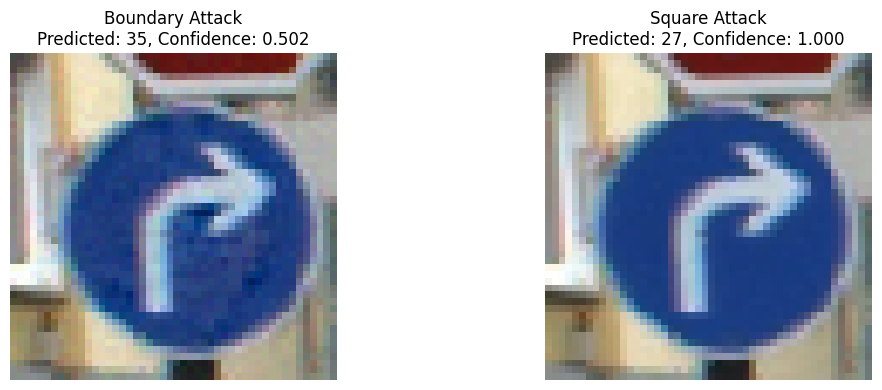

In [ ]:
# Step 14: Visualize original and adversarial images with predictions
import matplotlib.pyplot as plt

def plot_image_with_pred(img, label, conf, title):
    plt.imshow(img.squeeze())
    plt.title(f"{title}\nPredicted: {label}, Confidence: {conf:.3f}")
    plt.axis('off')

plt.figure(figsize=(12,4))
#plt.subplot(1,3,1)
#plot_image_with_pred(x_source, pred_label_clean, confidence_clean, "Original Image")

plt.subplot(1,2,1)
plot_image_with_pred(x_adv_boundary, pred_label_boundary, confidence_boundary, "Boundary Attack")

plt.subplot(1,2,2)
plot_image_with_pred(x_adv_square, pred_label_square, confidence_square, "Square Attack")

plt.tight_layout()
plt.show()

In [ ]:
# Step 15: Calculate and display L2 norm
import numpy as np

l2_norm_boundary = np.linalg.norm(x_source - x_adv_boundary)
l2_norm_square = np.linalg.norm(x_source - x_adv_square)

print(f"L2 norm (Source vs Boundary Attack): {l2_norm_boundary:.4f}")
print(f"L2 norm (Source vs Square Attack): {l2_norm_square:.4f}")

L2 norm (Source vs Boundary Attack): 1.9035
L2 norm (Source vs Square Attack): 0.0000


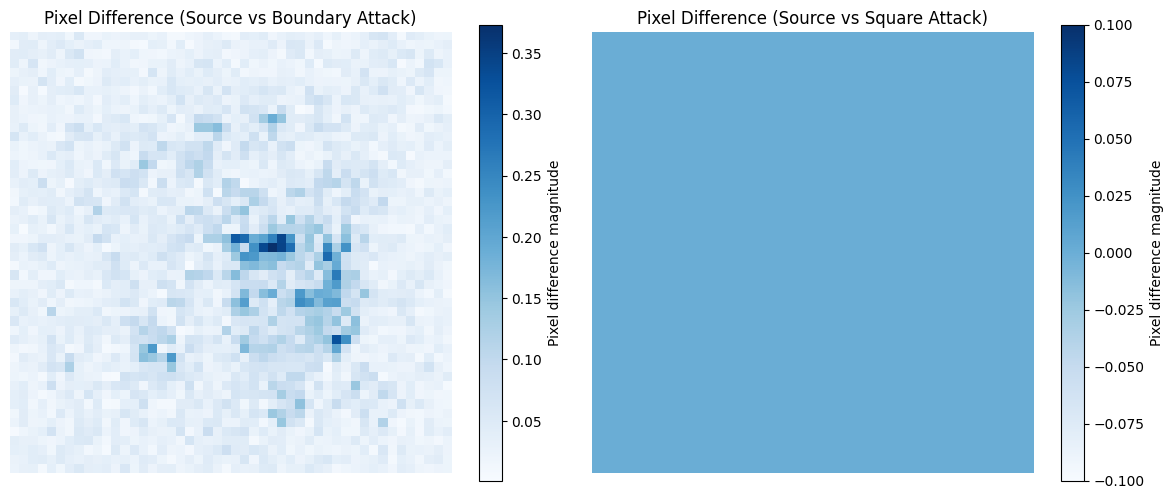

In [ ]:
# Step 16: Visualize pixel-wise difference

def plot_pixel_difference(img1, img2, title):
    # Calculate the absolute difference
    diff = np.abs(img1 - img2)
    # Sum over color channels to get a single difference value per pixel
    diff_magnitude = np.sum(diff, axis=-1)
    # Remove the batch dimension
    diff_magnitude = np.squeeze(diff_magnitude)


    plt.imshow(diff_magnitude, cmap='Blues', interpolation='nearest')
    plt.title(title)
    plt.colorbar(label='Pixel difference magnitude')
    plt.axis('off')

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plot_pixel_difference(x_source, x_adv_boundary, "Pixel Difference (Source vs Boundary Attack)")

plt.subplot(1, 2, 2)
plot_pixel_difference(x_source, x_adv_square, "Pixel Difference (Source vs Square Attack)")

plt.tight_layout()
plt.show()